In [1]:
import pandas as pd

url = 'https://raw.githubusercontent.com/Pdrsmth/automatidata-taxi-storytelling/main/course2_taxi_data.csv'
df = pd.read_csv(url)
print("Shape:", df.shape)
print("\nKolom:", df.columns.tolist())


Shape: (400000, 19)

Kolom: ['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance', 'RatecodeID', 'store_and_fwd_flag', 'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount', 'congestion_surcharge', 'airport_fee']


In [2]:
# Cleaning
df['tpep_pickup_datetime'] = pd.to_datetime(df['tpep_pickup_datetime'], errors='coerce')
df = df.dropna(subset=['tpep_pickup_datetime', 'fare_amount'])
df = df[(df['fare_amount'] > 0) & (df['trip_distance'] > 0)]
df['date'] = df['tpep_pickup_datetime'].dt.date
print(f"Setelah cleaning: {len(df):,} baris")

# Trip per hari
daily = df.groupby('date').size()
print(f"\nPeriode: {daily.index.min()} s/d {daily.index.max()} ({len(daily)} hari)")
print(f"Rata-rata trip/hari: {daily.mean():,.0f}")
print(f"Hari tersibuk: {daily.idxmax()} ({daily.max():,} trip)")
print(f"Hari tersepi: {daily.idxmin()} ({daily.min():,} trip)")
print(f"Selisih: {(daily.max()/daily.min()-1)*100:.0f}%")


Setelah cleaning: 397,379 baris

Periode: 2017-01-01 s/d 2017-01-31 (31 hari)
Rata-rata trip/hari: 12,819
Hari tersibuk: 2017-01-28 (15,178 trip)
Hari tersepi: 2017-01-02 (9,180 trip)
Selisih: 65%


             trips   avg_fare
is_weekend                   
False       282350  12.301561
True        115029  12.050064

Weekday: 71% dari semua trip


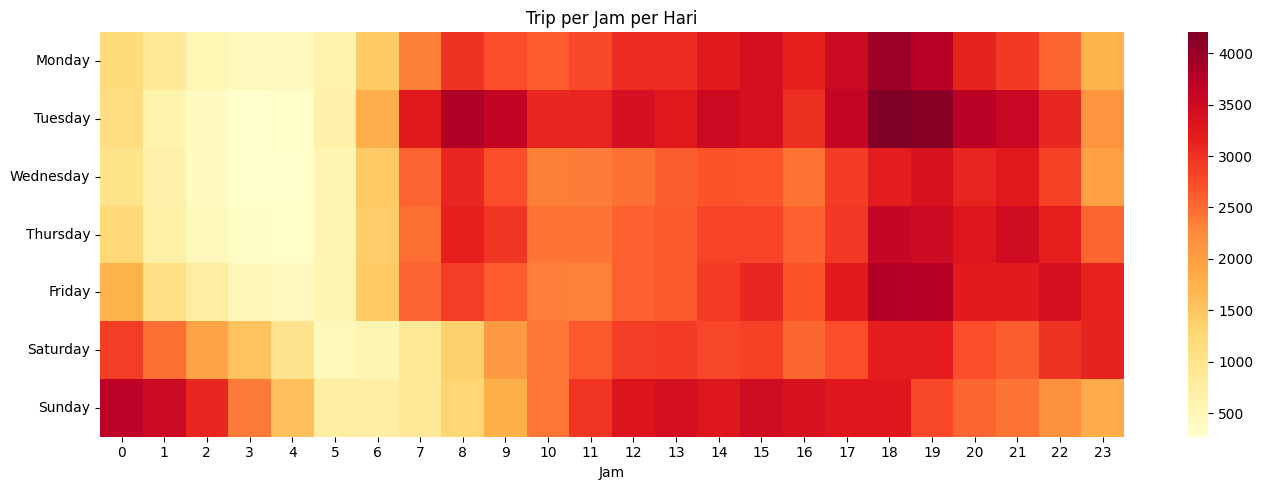

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

df['dow'] = df['tpep_pickup_datetime'].dt.day_name()
df['hour'] = df['tpep_pickup_datetime'].dt.hour
df['is_weekend'] = df['dow'].isin(['Saturday', 'Sunday'])

# Weekday vs weekend
ww = df.groupby('is_weekend').agg(trips=('fare_amount', 'size'), avg_fare=('fare_amount', 'mean'))
print(ww)
print(f"\nWeekday: {ww.loc[False, 'trips']/ww['trips'].sum()*100:.0f}% dari semua trip")

# Heatmap jam x hari
order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
df['dow'] = pd.Categorical(df['dow'], categories=order, ordered=True)
piv = df.groupby(['dow', 'hour'], observed=True).size().unstack(fill_value=0)

plt.figure(figsize=(14, 5))
sns.heatmap(piv, cmap='YlOrRd')
plt.title('Trip per Jam per Hari')
plt.xlabel('Jam'); plt.ylabel('')
plt.tight_layout()
plt.show()


In [4]:
plt.savefig('c2_heatmap.png', dpi=150, bbox_inches='tight')
print("Tersimpan!")


Tersimpan!


<Figure size 640x480 with 0 Axes>